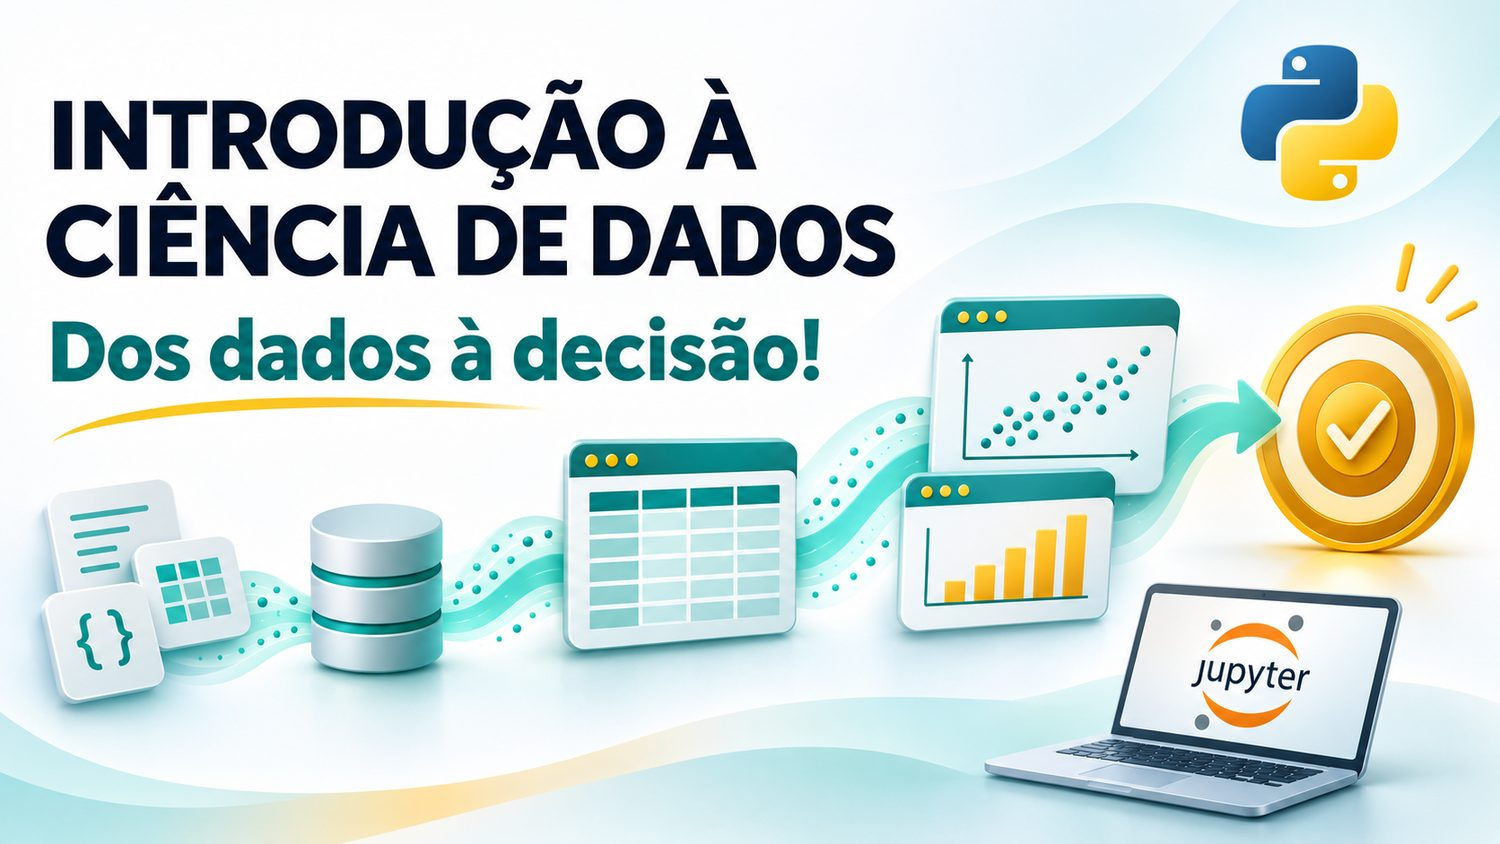

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/04_Dados_Imperfeitos_e_Processo.ipynb)

# Capítulo 4 – Dados imperfeitos e o processo de trabalho

Até aqui tratámos os dados como se fossem um retrato fiel do que aconteceu. Não são. Este capítulo mostra de onde vêm os dados, quatro formas de eles nos enganarem (cada uma simulada, para veres o efeito) e o processo de trabalho que a maioria dos projetos segue, o CRISP-DM.

> **Objetivos:** identificar fontes de dados e o que cada uma consegue mostrar; reconhecer dados incompletos, ruidosos, enviesados e dependentes do contexto; descrever as seis fases do CRISP-DM e a razão de ser um ciclo; perceber onde se gasta o tempo num projeto; aplicar práticas básicas de reprodutibilidade.

**Pré-requisitos:** capítulos 1 a 3.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_consultas(n=10_000, semente=42):
    """Gera marcações de consultas de uma clínica fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    antecedencia = rng.gamma(2.0, 9.0, n).round().clip(0, 90).astype(int)
    idade = rng.integers(18, 90, n)
    faltas_anteriores = rng.poisson(0.4, n)
    dia = rng.choice(["seg", "ter", "qua", "qui", "sex"], n)
    # A clínica envia mais lembretes por SMS a quem já faltou antes
    lembrete = rng.random(n) < 0.05 + 0.70 * (faltas_anteriores >= 1)
    z = (-3.7 + 0.05 * antecedencia + 1.0 * faltas_anteriores
         - 0.012 * (idade - 18) - 0.6 * lembrete + 0.3 * (dia == "seg"))
    faltou = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"antecedencia_dias": antecedencia, "idade": idade,
                         "faltas_anteriores": faltas_anteriores, "dia_semana": dia,
                         "lembrete": lembrete, "faltou": faltou})


consultas = gerar_consultas()
consultas.head()

,antecedencia_dias,idade,faltas_anteriores,dia_semana,lembrete,faltou
0,19,55,2,qua,True,False
1,26,42,2,sex,True,False
2,17,48,0,ter,False,False
3,15,34,1,ter,False,False
4,28,43,0,sex,False,False


## De onde vêm os dados

| Fonte | Exemplo na clínica | O que mostra bem | O que esconde |
| --- | --- | --- | --- |
| Registos administrativos | Marcações, faltas, faturação | O que foi registado, para toda a gente | Os motivos |
| Inquéritos e questionários | Satisfação após a consulta | Opiniões e motivos | Quem não respondeu |
| Transações | Pagamentos | Valores exatos e datas | Quem não chegou a pagar |
| Sensores e dispositivos | Leitor de cartões à entrada | Horas exatas | Tudo o que o sensor não mede |
| Plataformas digitais | Marcações pela aplicação | Comportamento passo a passo | Quem marca por telefone |
| Experiências | Sortear quem recebe lembrete | Causas | Custam tempo e nem sempre são possíveis |
| Estudos observacionais | Acompanhar pacientes durante um ano | Evolução ao longo do tempo | Causas (há variáveis de confusão) |
| Decisões e classificações humanas | A rececionista anota «desmarcou em cima da hora» | Contexto e juízo | Critérios diferentes de pessoa para pessoa |

Cada fonte produz **uma** representação da realidade, com as suas variáveis e os seus pontos cegos. A mesma pergunta pode ter respostas diferentes conforme a fonte.

## Os dados não são a realidade

Entre o que acontece no mundo e a tabela que analisamos há sempre um processo de recolha e de medição. Esse processo falha de quatro maneiras.

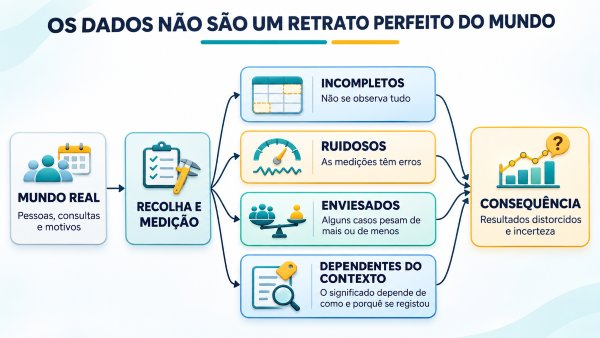

Vamos simular cada um dos quatro problemas, para ver quanto distorcem uma conclusão.

### Incompletos: o que falta não falta ao acaso

A clínica decide registar o motivo das faltas. Só o consegue fazer quando o paciente atende a chamada de seguimento, e quem falta por desinteresse atende menos.

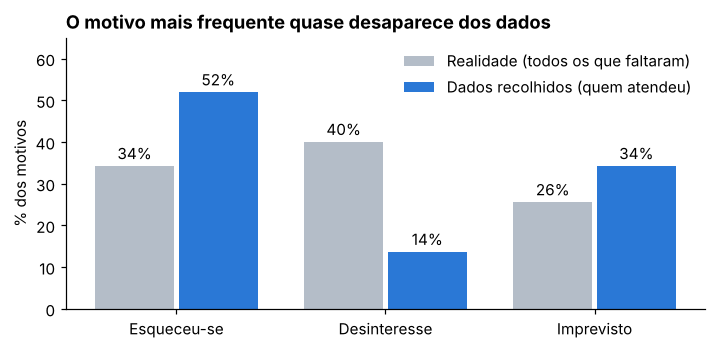

Responderam 52% dos pacientes que faltaram.


In [3]:
rng = np.random.default_rng(7)
faltosos = consultas[consultas["faltou"]].copy()
faltosos["motivo"] = rng.choice(["Esqueceu-se", "Desinteresse", "Imprevisto"], len(faltosos), p=[0.35, 0.40, 0.25])
atende = {"Esqueceu-se": 0.75, "Desinteresse": 0.20, "Imprevisto": 0.70}
faltosos["respondeu"] = rng.random(len(faltosos)) < faltosos["motivo"].map(atende)

real = faltosos["motivo"].value_counts(normalize=True) * 100
observado = faltosos[faltosos["respondeu"]]["motivo"].value_counts(normalize=True) * 100
comparacao = pd.DataFrame({"Realidade": real, "Dados recolhidos": observado}).loc[["Esqueceu-se", "Desinteresse", "Imprevisto"]]

x = np.arange(3)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
b1 = ax.bar(x - 0.2, comparacao["Realidade"], 0.38, color=CINZA, label="Realidade (todos os que faltaram)")
b2 = ax.bar(x + 0.2, comparacao["Dados recolhidos"], 0.38, color=AZUL, label="Dados recolhidos (quem atendeu)")
ax.bar_label(b1, fmt="%.0f%%", padding=2)
ax.bar_label(b2, fmt="%.0f%%", padding=2)
ax.set_xticks(x, comparacao.index)
ax.set_ylabel("% dos motivos")
ax.set_ylim(0, 65)
ax.set_title("O motivo mais frequente quase desaparece dos dados")
ax.legend(frameon=False, loc="upper right")
plt.show()

print(f"Responderam {faltosos['respondeu'].mean():.0%} dos pacientes que faltaram.")

Nos dados recolhidos, o esquecimento parece ser a causa principal, e a clínica investiria em lembretes. Na realidade, a causa principal é o desinteresse, que os lembretes não resolvem. Os valores em falta não se distribuem ao acaso: **faltam precisamente os casos que mais interessam**.

> Antes de analisar, pergunta sempre: **quem ou o que não está nesta tabela, e porquê?**

### Ruidosos: os erros de medição escondem as relações

A antecedência das marcações é registada à mão em algumas unidades, com enganos. Vamos acrescentar ruído e ver o que acontece à relação com as faltas.

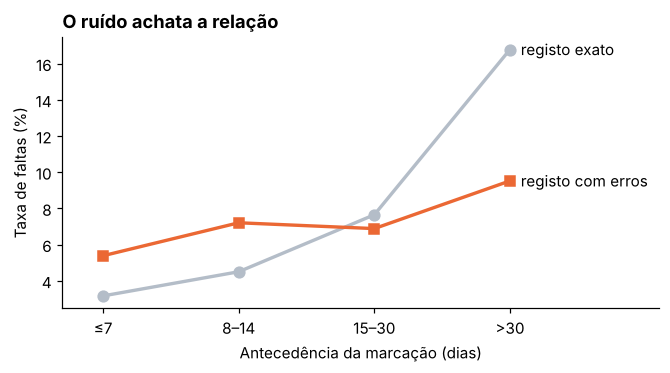

In [4]:
def taxa_por_antecedencia(antecedencia):
    faixas = pd.cut(antecedencia.clip(0, 90), [-1, 7, 14, 30, 90], labels=["≤7", "8–14", "15–30", ">30"])
    return consultas.groupby(faixas, observed=True)["faltou"].mean() * 100


rng = np.random.default_rng(3)
limpa = taxa_por_antecedencia(consultas["antecedencia_dias"])
ruidosa = taxa_por_antecedencia(consultas["antecedencia_dias"] + rng.normal(0, 25, len(consultas)))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(limpa.index.astype(str), limpa, color=CINZA, lw=2.2, marker="o", ms=7)
ax.plot(ruidosa.index.astype(str), ruidosa, color=LARANJA, lw=2.2, marker="s", ms=7)
ax.text(3.08, limpa.iloc[-1], "registo exato", va="center")
ax.text(3.08, ruidosa.iloc[-1], "registo com erros", va="center")
ax.set_xlim(-0.3, 4.1)
ax.set_xlabel("Antecedência da marcação (dias)")
ax.set_ylabel("Taxa de faltas (%)")
ax.set_title("O ruído achata a relação")
plt.show()

A relação continua lá, mas parece muito mais fraca. O ruído numa variável faz com que o seu efeito seja **subestimado**. Um analista que só visse a linha laranja podia concluir que a antecedência importa pouco.

### Enviesados: a amostra não representa o todo

A clínica faz um inquérito de satisfação à saída da consulta e conclui que os pacientes estão satisfeitos com o sistema de marcações. Mas quem responde à saída é quem compareceu.

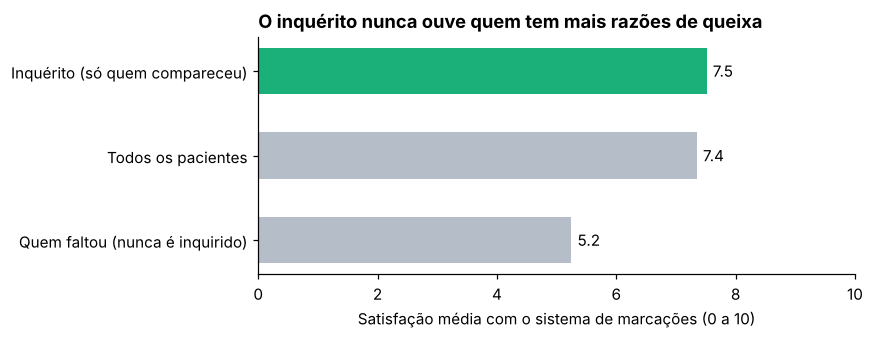

In [5]:
rng = np.random.default_rng(11)
# Satisfação com as marcações (0 a 10): desce com a antecedência e é mais baixa em quem falta
satisfacao = (8.2 - 0.04 * consultas["antecedencia_dias"] - 1.8 * consultas["faltou"]
              + rng.normal(0, 1.2, len(consultas))).clip(0, 10)

todos_pacientes = satisfacao.mean()
so_presentes = satisfacao[~consultas["faltou"]].mean()
so_faltosos = satisfacao[consultas["faltou"]].mean()

fig, ax = plt.subplots(figsize=(7, 2.8))
barras = ax.barh(["Quem faltou (nunca é inquirido)", "Todos os pacientes", "Inquérito (só quem compareceu)"],
                 [so_faltosos, todos_pacientes, so_presentes], color=[CINZA, CINZA, VERDE], height=0.55)
ax.bar_label(barras, fmt="%.1f", padding=4)
ax.set_xlim(0, 10)
ax.set_xlabel("Satisfação média com o sistema de marcações (0 a 10)")
ax.set_title("O inquérito nunca ouve quem tem mais razões de queixa")
plt.show()

A diferença na média é pequena, porque quem falta é uma minoria. O problema é outro: o grupo cuja opinião mais importava para resolver as faltas está **totalmente ausente** do inquérito. A isto chama-se **enviesamento de seleção**: a forma como os dados foram recolhidos exclui sistematicamente uma parte da população.

### Dependentes do contexto: o que quer dizer «falta»?

A coluna `faltou` parece inequívoca. Mas o valor depende de uma definição que alguém escolheu. Um paciente que desmarca duas horas antes faltou? E um que chega 40 minutos atrasado e já não é atendido?

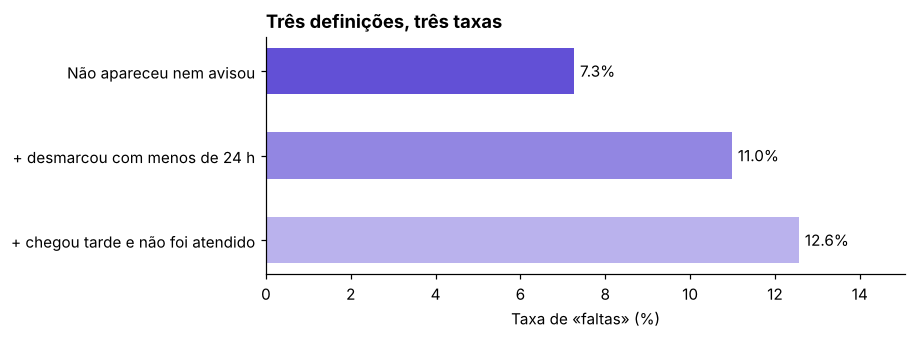

In [6]:
rng = np.random.default_rng(5)
n = len(consultas)
desmarcou_tarde = (~consultas["faltou"]) & (rng.random(n) < 0.04)      # desmarcou com menos de 24 h
chegou_atrasado = (~consultas["faltou"]) & ~desmarcou_tarde & (rng.random(n) < 0.02)

definicoes = pd.Series({
    "Não apareceu nem avisou": consultas["faltou"].mean(),
    "+ desmarcou com menos de 24 h": (consultas["faltou"] | desmarcou_tarde).mean(),
    "+ chegou tarde e não foi atendido": (consultas["faltou"] | desmarcou_tarde | chegou_atrasado).mean()}) * 100

fig, ax = plt.subplots(figsize=(7.5, 2.8))
barras = ax.barh(definicoes.index, definicoes, color=[VIOLETA, VIOLETA + "b0", VIOLETA + "70"], height=0.55)
ax.bar_label(barras, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, definicoes.max() * 1.2)
ax.set_xlabel("Taxa de «faltas» (%)")
ax.set_title("Três definições, três taxas")
plt.show()

Nenhuma das três definições está errada. Mas duas clínicas que usem definições diferentes não são comparáveis, e uma clínica que mude de definição a meio do ano vai ver uma «subida» das faltas que nunca aconteceu.

Há uma segunda armadilha: muitas vezes não se consegue medir o que interessa e mede-se outra coisa no seu lugar. À variável que substitui chama-se **variável substituta** (*proxy*). A clínica quer saber quantas vagas se desperdiçam; mede faltas. Mas uma falta em que a vaga foi ocupada por outro paciente em lista de espera não desperdiçou nada.

> Para cada variável, pergunta: **quem a registou, com que regra e para que fim?**

### Resumo

| Problema | Sinal de alerta | O que fazer |
| --- | --- | --- |
| Incompletos | Muitos valores em falta; grupos que não aparecem | Perceber porque faltam antes de os ignorar ou preencher |
| Ruidosos | Valores impossíveis; registos manuais; relações mais fracas do que seria de esperar | Validar, corrigir na origem, medir várias vezes |
| Enviesados | Dados recolhidos só de quem aparece, responde ou compra | Comparar a amostra com a população; procurar os ausentes |
| Dependentes do contexto | Definições que mudam entre equipas ou ao longo do tempo | Escrever a definição de cada variável; confirmar com quem a regista |

## O processo de trabalho: CRISP-DM

O **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*) é o modelo de processo mais usado em projetos de dados. Foi criado no final dos anos 1990 por um consórcio de empresas e continua a ser a referência. Tem seis fases, com os dados no centro.

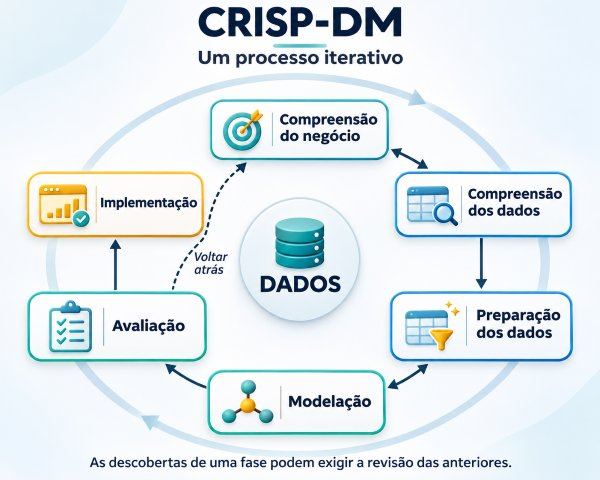

| Fase | Pergunta central | Trabalho típico | Capítulo |
| --- | --- | --- | --- |
| **1. Compreensão do negócio** | Que problema e que decisão? | Enquadrar, definir critérios de sucesso, identificar restrições | 2 e 3 |
| **2. Compreensão dos dados** | Que dados há e o que representam? | Recolher, explorar, verificar a qualidade | 1 e 4 |
| **3. Preparação dos dados** | Como os pomos em condições? | Limpar, juntar tabelas, criar variáveis | módulos seguintes |
| **4. Modelação** | Que técnica responde à pergunta? | Escolher, treinar e comparar modelos | 3 |
| **5. Avaliação** | Serve o objetivo, e não só a métrica? | Comparar com a linha de base, pesar os custos dos erros | 3 |
| **6. Implementação** | Como chega a quem decide? | Relatório, painel ou sistema; acompanhar e manter | módulos seguintes |

Três coisas a reter sobre o esquema:

- **As setas duplas.** Compreender o negócio e compreender os dados fazem-se em vaivém: os dados mostram que a pergunta estava mal feita, e a nova pergunta pede outros dados. O mesmo acontece entre preparação e modelação.
- **A seta tracejada.** A avaliação pode mandar-nos de volta ao início. Foi o que aconteceu no capítulo 3: o modelo tinha boa exatidão e só ao avaliar a decisão percebemos que a pergunta útil era outra.
- **O círculo exterior.** Um projeto implementado gera novos dados e novas perguntas. O processo recomeça.

> **Percorrer o ciclo todo sem resolver o problema não é um fracasso.** Concluir, com evidência, que os dados disponíveis não respondem à pergunta é um resultado útil: evita que se tome uma decisão com base numa ilusão.

### Onde se gasta o tempo

É comum pensar que o trabalho de um cientista de dados é construir modelos. Um inquérito muito citado, feito pela CrowdFlower a cientistas de dados em 2016, mostra outra coisa.

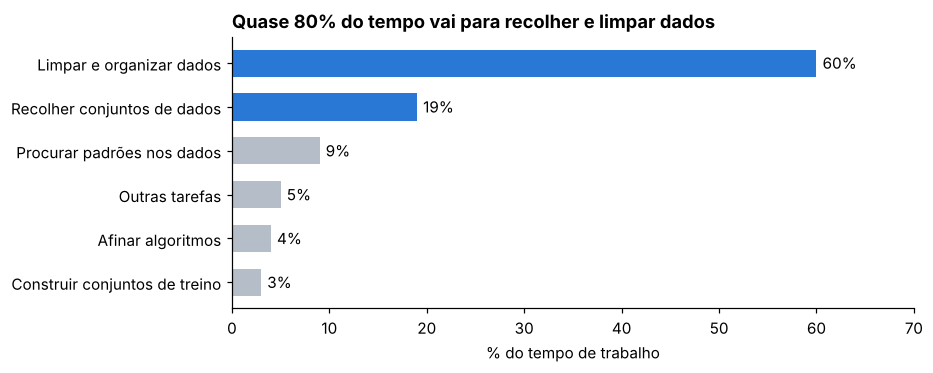

In [7]:
tempo = pd.Series({"Limpar e organizar dados": 60, "Recolher conjuntos de dados": 19,
                   "Procurar padrões nos dados": 9, "Outras tarefas": 5,
                   "Afinar algoritmos": 4, "Construir conjuntos de treino": 3})
cores = [AZUL, AZUL, CINZA, CINZA, CINZA, CINZA]

fig, ax = plt.subplots(figsize=(8, 3.2))
barras = ax.barh(tempo.index, tempo, color=cores, height=0.62)
ax.bar_label(barras, fmt="%d%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 70)
ax.set_xlabel("% do tempo de trabalho")
ax.set_title("Quase 80% do tempo vai para recolher e limpar dados")
plt.show()

<sub>Fonte: CrowdFlower, <i>Data Science Report</i>, 2016.</sub>

A recolha e a limpeza ocupam 79% do tempo. Afinar algoritmos, a parte mais conhecida, ocupa 4%. A conclusão prática é que as três primeiras fases do CRISP-DM merecem a maior parte da atenção: um modelo sofisticado não compensa uma pergunta mal feita nem dados mal preparados.

## Ferramentas e reprodutibilidade

Uma análise feita à mão numa folha de cálculo funciona uma vez. Um projeto de ciência de dados precisa de ferramentas programáveis por seis razões:

- os dados podem ser grandes e complexos;
- a preparação é repetitiva, e a repetição manual gera erros;
- a exploração exige muitas tentativas;
- os modelos têm de ser treinados e avaliados de forma sistemática;
- outra pessoa (ou tu, daqui a seis meses) tem de conseguir **repetir** a análise e chegar ao mesmo resultado;
- a análise vai ser retomada e alargada.

Este tutorial usa **Python**, por ser aberto, legível e ter as bibliotecas de referência para dados (NumPy, pandas, SciPy, scikit-learn, matplotlib), e **notebooks Jupyter**, que juntam no mesmo documento o texto, o código, os resultados e os gráficos. A instalação e as bases da linguagem estão no tutorial [Introdução ao Python](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python).

### Três hábitos de reprodutibilidade

**1. Fixar a semente dos números aleatórios.** Sem semente, cada execução dá um resultado diferente.

In [8]:
for execucao in (1, 2):
    print(f"Sem semente, execução {execucao}:", np.random.default_rng().integers(0, 100, 5).tolist())
for execucao in (1, 2):
    print(f"Com semente, execução {execucao}:", np.random.default_rng(42).integers(0, 100, 5).tolist())

Sem semente, execução 1: [33, 0, 5, 28, 89]
Sem semente, execução 2: [42, 67, 31, 60, 12]
Com semente, execução 1: [8, 77, 65, 43, 43]
Com semente, execução 2: [8, 77, 65, 43, 43]


**2. Registar as versões das bibliotecas.** Um resultado pode mudar entre versões.

In [9]:
import matplotlib
import sklearn

for biblioteca in (np, pd, matplotlib, sklearn):
    print(f"{biblioteca.__name__:<12} {biblioteca.__version__}")

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
sklearn      1.9.1


**3. Executar o notebook de cima a baixo antes de o partilhar.** Um notebook executado por ordem diferente pode mostrar resultados que já não correspondem ao código. No Jupyter: *Kernel → Restart & Run All*. No Colab: *Tempo de execução → Reiniciar sessão e executar tudo*.

## Exercícios

### `Exercício 1` – Que problema é?

Classifica cada situação como dados incompletos, ruidosos, enviesados ou dependentes do contexto:

1. Uma aplicação de saúde conclui que os portugueses dão 9 000 passos por dia, com base nos seus utilizadores.
2. Num hospital, «tempo de espera» conta desde a triagem; noutro, desde a entrada.
3. Num inquérito sobre rendimentos, 30% das pessoas com rendimentos mais altos não responderam à pergunta.
4. Os pesos de recém-nascidos numa maternidade terminam quase todos em 0 ou em 5.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Enviesados**: quem usa uma aplicação de passos não representa a população.
2. **Dependentes do contexto**: a mesma variável tem definições diferentes.
3. **Incompletos**, e não ao acaso: faltam os valores mais altos, por isso a média fica subestimada.
4. **Ruidosos**: os valores foram arredondados no registo.

</details>

### `Exercício 2` – Quanto ruído é de mais?

Repete a simulação do ruído com desvios padrão de 5, 15 e 40 dias. A partir de que nível deixa de se ver a relação entre antecedência e faltas?

In [10]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
rng = np.random.default_rng(3)
fig, ax = plt.subplots(figsize=(7, 3.2))
for desvio, cor in [(0, CINZA), (5, AZUL), (15, VERDE), (40, LARANJA)]:
    ruido = rng.normal(0, desvio, len(consultas)) if desvio else 0
    taxas = taxa_por_antecedencia(consultas["antecedencia_dias"] + ruido)
    ax.plot(taxas.index.astype(str), taxas, color=cor, marker="o", label=f"desvio de {desvio} dias")
ax.set_ylabel("Taxa de faltas (%)")
ax.legend(frameon=False)
plt.show()
```

Com 5 dias de desvio quase não se nota diferença. Com 15, a relação enfraquece. Com 40, a linha fica quase plana: o ruído é da mesma ordem de grandeza da variável e a informação perde-se.

</details>

### `Exercício 3` – Em que fase estou?

Indica a fase do CRISP-DM de cada tarefa:

1. Juntar a tabela de marcações com a tabela de pacientes.
2. Reunir com a direção da clínica para saber quantas chamadas a receção consegue fazer.
3. Comparar o custo total de três limiares.
4. Descobrir que 12% das marcações não têm idade registada.
5. Entregar à receção, todas as manhãs, a lista de pacientes a contactar.
6. Treinar uma regressão logística.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Preparação dos dados.
2. Compreensão do negócio.
3. Avaliação.
4. Compreensão dos dados.
5. Implementação.
6. Modelação.

</details>

### `Exercício 4` – Um projeto que «falhou»

Uma equipa passou dois meses a tentar prever avarias de máquinas e concluiu que os registos de manutenção não têm informação suficiente: metade das avarias nunca foi registada. A direção considera o projeto um fracasso. Escreve duas ou três frases a defender que não foi.

<details>
<summary><b>Ver uma solução possível</b></summary>

O projeto respondeu a uma pergunta que ninguém tinha feito: os registos de manutenção não são fiáveis. Sem essa conclusão, a empresa teria continuado a decidir com base em dados que escondem metade das avarias. O passo seguinte é claro e barato (registar todas as avarias durante seis meses), e só depois faz sentido voltar a tentar a previsão.

</details>

## Verifica o que aprendeste

- [ ] Sei indicar várias fontes de dados e o que cada uma esconde.
- [ ] Sei explicar porque os dados são uma representação da realidade, e não a realidade.
- [ ] Sei reconhecer dados incompletos, ruidosos, enviesados e dependentes do contexto.
- [ ] Sei o que é enviesamento de seleção e o que é uma variável substituta.
- [ ] Sei enumerar as seis fases do CRISP-DM, por ordem, e explicar porque é um ciclo.
- [ ] Sei em que fases se gasta a maior parte do tempo de um projeto.
- [ ] Sei aplicar três hábitos de reprodutibilidade.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Cross-industry_standard_process_for_data_mining
- https://en.wikipedia.org/wiki/Selection_bias
- https://en.wikipedia.org/wiki/Missing_data
- https://docs.jupyter.org/en/latest/